# IE7615 Discriminative Project, Milestone 2 (Group 7)
## Multi-object detection with a custom-trained YOLOv8

| Requirement | Where it is met |
|---|---|
| ≥ 100 multi-object images per student, built by concatenating single-object photos; augmentation allowed | §5: 2×2, 3×3, 4×4, 5×4 and 5×5 grids of 224×224 photos, generated per member (file names start with the member's initials) |
| Bounding boxes for the objects | §4: **two open-vocabulary detectors (Grounding DINO + YOLO-World) check each other**; disagreements are settled by the Milestone 1 ConvNeXt classifier; samples are checked by eye; excluded photos are reported per Object ID |
| Custom-train YOLOv8 | §6: YOLOv8s, `imgsz=1120` (the largest grid), `batch=8`, checkpoints on Google Drive with automatic resume |
| Given an image, report the IDs and locations of all objects | §8: `detect_objects()` returns Object ID, name, confidence and box for every object |
| Metrics | §7: mAP@0.5, mAP@0.5:0.95, precision, recall (overall **and per grid size**), per-class AP, confusion matrix, example detections |

**TA dataset notes handled in code:** exact duplicates removed **before** splitting; the non-224 OBJ003 image is resized; `OBJ054_017` is excluded; hard photos (small, far, cluttered) are kept and only left out when no reliable box can be made (≤ 20 %, reported per Object ID); no source photo appears in more than one split.

**How to run:** Runtime → Change runtime type → **T4 GPU** → Run all. Everything slow (labels, dataset, training) is saved to Google Drive, so after a disconnect *Run all* continues where it stopped.

## 1. Setup

In [1]:
!pip -q install "ultralytics>=8.3.0" "transformers>=4.40"
!nvidia-smi -L || echo "No GPU: switch the runtime to T4 GPU"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 19.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 3.8 MB/s eta 0:00:00
GPU 0: Tesla T4 (UUID: GPU-7d710a19-77a4-268e-defd-29981b9af7b2)


In [2]:
import os, re, io, json, math, time, random, shutil, hashlib, zipfile, subprocess, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps, ImageFilter, ImageEnhance, ImageDraw
from sklearn.model_selection import train_test_split
warnings.filterwarnings("ignore")
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)

try:
    import google.colab  # noqa
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# ---------------- paths ----------------
ZIP_PATH      = os.environ.get("IE_ZIP", "/content/drive/MyDrive/IE7615DeepLearning.zip")      # TA dataset zip
OBJECTS_SHEET = os.environ.get("IE_SHEET", "/content/drive/MyDrive/Milestone-1 _ OBJECTS.xlsx")  # shared sheet (xlsx or csv)
EXTRACT_DIR   = Path(os.environ.get("IE_DATA_DIR", "/content/data"))                           # local unzip target
SAVE_DIR      = Path(os.environ.get("IE_SAVE_DIR", "/content/drive/MyDrive/IE7615_project_M2"))  # everything that must survive
WORK_DIR      = Path(os.environ.get("IE_WORK_DIR", "/content/m2_work"))                         # fast local disk
YOLO_DIR      = WORK_DIR / "yolo_dataset"
RUNS_DIR      = SAVE_DIR / "runs"
EVAL_DIR      = SAVE_DIR / "eval"
FIG_DIR       = SAVE_DIR / "figures"

# Milestone 1 classifier (used only to CHECK boxes). Taken from Drive, or downloaded from our GitHub release.
CLF_CKPT      = Path(os.environ.get("IE_CLF", "/content/drive/MyDrive/IE7615_project_v3/checkpoints/E_ConvNeXtT_best.pt"))
CLF_URL       = "https://github.com/tanmayi123/Discriminative-Project-Deep-Learning/releases/download/v1.0-weights/final_E_ConvNeXtT_best.pt"

# ---------------- scope ----------------
USE_SECTION_01 = False      # True = only the 38 objects marked SECTION-01 in the shared sheet
SUBSET_IDS     = None       # or an explicit list such as ["OBJ001", "OBJ005"]; None = all objects

# ---------------- data fixes ----------------
SEED       = 42
TILE       = 224
BG_REGEX   = re.compile(r"_bg_?\d|bg\d+", re.IGNORECASE)          # background-only shots (_bg_001, BG001)
REMOVE_STEMS     = {"OBJ054_017"}                                  # TA: not a photo of the object
OBJ004_BG_STEMS  = {"OBJ004_007", "OBJ004_014", "OBJ004_023", "OBJ004_030", "OBJ004_073"}   # untagged backgrounds (no toy car)
EXCLUDE_BG_STEMS = {"OBJ035_bg_002", "OBJ049_bg_001"}             # background photos that show a registered object

# ---------------- labelling ----------------
GD_MODEL      = "IDEA-Research/grounding-dino-tiny"
YW_MODEL      = "yolov8s-worldv2.pt"
GD_BOX_THR, GD_TEXT_THR = 0.20, 0.20
YW_CONF       = 0.05
AGREE_IOU     = 0.50        # the two detectors agree if their boxes overlap this much
CLF_MIN       = 0.40        # classifier probability of the photo's own ID needed to confirm a single box
MIN_BOX_SIDE  = 8           # pixels
MAX_EXCLUDED  = 0.20        # TA limit on left-out object photos
# Plain-English prompts where the sheet name is a brand, a typo or unclear to a detector
PROMPT_OVERRIDES = {"OBJ009": "speaker", "OBJ016": "portable ssd", "OBJ017": "game controller",
                    "OBJ020": "airpods", "OBJ031": "card box", "OBJ040": "hair claw clip",
                    "OBJ043": "swimming goggles", "OBJ046": "smart watch", "OBJ056": "tote bag"}
MANUAL_BOXES_CSV = SAVE_DIR / "manual_boxes.csv"   # optional: path stem,x0,y0,x1,y1 drawn by hand (overrides auto)
MANUAL_REJECT    = set()                           # stems whose auto box was wrong in the visual check

# ---------------- grids (per member and split): (columns, rows) -> count ----------------
MEMBERS = {"MH": "Mukul Sridar Haladhi", "PK": "Praniti Sunil Kale",
           "SC": "Santhoshkumar Chandrasekar", "TS": "Tanmayi Shurpali"}
GRID_COUNTS = {"train": {(2, 2): 60, (3, 3): 50, (4, 4): 40, (5, 4): 25, (5, 5): 25},
               "val":   {(2, 2): 10, (3, 3): 10, (4, 4): 10, (5, 4): 10, (5, 5): 10},
               "test":  {(2, 2): 10, (3, 3): 10, (4, 4): 10, (5, 4): 10, (5, 5): 10}}
BG_TILE_P  = 0.10           # chance a cell holds a background-only photo (no box): teaches "nothing here"
AUG_P      = 0.70           # chance a TRAIN tile is augmented (val/test tiles are never augmented)
REGENERATE = False          # True = rebuild the grid dataset even if a saved copy exists

# ---------------- YOLO ----------------
MODEL    = "yolov8s.pt"
IMGSZ    = 1120             # TA tip: close to the largest grid (5x5 = 1120 x 1120)
BATCH    = 8                # lower to 4 if CUDA runs out of memory
EPOCHS   = 80
PATIENCE = 20
QUICK_TEST = False          # True = 5 classes, few images, 2 epochs: a fast dry run of the whole notebook
if QUICK_TEST:
    GRID_COUNTS = {s: {k: (3 if s == "train" else 1) for k in GRID_COUNTS[s]} for s in GRID_COUNTS}
    EPOCHS = 2

def seed_everything(s=SEED):
    random.seed(s); np.random.seed(s)
seed_everything()
print("Colab:", IN_COLAB, "| results ->", SAVE_DIR)

Colab: True | results -> /content/drive/MyDrive/IE7615_project_M2


In [3]:
# Mount Drive and unzip the dataset to local disk (skipped if already there)
if IN_COLAB:
    from google.colab import drive
    if not os.path.ismount("/content/drive"):
        if os.path.exists("/content/drive"):
            shutil.rmtree("/content/drive")            # stray local folder from an earlier failed mount
        drive.mount("/content/drive")
    if not (EXTRACT_DIR.is_dir() and any(EXTRACT_DIR.iterdir())):
        assert os.path.exists(ZIP_PATH), f"Dataset zip not found at {ZIP_PATH}"
        EXTRACT_DIR.mkdir(parents=True, exist_ok=True)
        subprocess.run(["unzip", "-q", "-o", ZIP_PATH, "-d", str(EXTRACT_DIR)], check=True)
    print("Data in", EXTRACT_DIR)

Mounted at /content/drive
Data in /content/data


In [4]:
for d in (SAVE_DIR, WORK_DIR, RUNS_DIR, EVAL_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)
print("Folders ready")

Folders ready


## 2. Data cleaning
Labels always come from the folder name. Steps: skip junk files → verify every image → remove `OBJ054_017` → mark background-only photos (filename tags, plus the five untagged OBJ004 backgrounds) → **exact duplicates removed before the split** (MD5) → background photos that are byte-identical to an object photo, or that show a registered object, are dropped from the negatives. Images that are not 224×224 (one in OBJ003) are resized when loaded.

In [5]:
IMG_EXT   = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}
OBJ_RE    = re.compile(r"OBJ[_\- ]?0*(\d+)", re.IGNORECASE)
JUNK      = {"__MACOSX", ".[assistant]", ".ipynb_checkpoints", ".git"}
def is_junk(n): return n.startswith(".") or n in JUNK
def obj_id(s):
    m = OBJ_RE.search(str(s)); return f"OBJ{int(m.group(1)):03d}" if m else None

def find_class_root(base):
    best, best_n = None, 0
    for root, dirs, _ in os.walk(base):
        dirs[:] = [d for d in dirs if not is_junk(d)]
        n = sum(1 for d in dirs if obj_id(d))
        if n > best_n: best, best_n = Path(root), n
    return best, best_n

CLASS_ROOT, n_dirs = find_class_root(EXTRACT_DIR)
rows, junk = [], 0
for cdir in sorted(p for p in CLASS_ROOT.iterdir() if p.is_dir() and not is_junk(p.name) and obj_id(p.name)):
    for root, dirs, files in os.walk(cdir):
        dirs[:] = [d for d in dirs if not is_junk(d)]
        for f in sorted(files):
            if f.startswith(".") or Path(f).suffix.lower() not in IMG_EXT: junk += 1; continue
            rows.append({"path": str(Path(root, f)), "object_id": obj_id(cdir.name), "fname": f, "stem": Path(f).stem})
raw = pd.DataFrame(rows)

def readable(p):
    try:
        with Image.open(p) as im: im.verify()
        return True
    except Exception:
        return False
raw["ok"] = [readable(p) for p in raw.path]
df = raw[raw.ok].copy()
removed = df[df.stem.isin(REMOVE_STEMS)]
df = df[~df.stem.isin(REMOVE_STEMS)]
df["is_bg"] = df.fname.str.contains(BG_REGEX) | df.stem.isin(OBJ004_BG_STEMS)
df["md5"] = [hashlib.md5(Path(p).read_bytes()).hexdigest() for p in df.path]

obj_df, bg_df = df[~df.is_bg].copy(), df[df.is_bg].copy()
conflict = obj_df.groupby("md5").object_id.nunique(); conflict = set(conflict[conflict > 1].index)
n_conflict = int(obj_df.md5.isin(conflict).sum()); obj_df = obj_df[~obj_df.md5.isin(conflict)]
n0 = len(obj_df)
obj_df = (obj_df.assign(_copy=obj_df.fname.str.contains(r" ?\(\d+\)\.[^.]+$"))
                .sort_values(["_copy", "path"]).drop_duplicates("md5").drop(columns="_copy"))
n_dup = n0 - len(obj_df)

fake_bg = bg_df[bg_df.md5.isin(set(obj_df.md5))]
bg_df = bg_df[~bg_df.md5.isin(set(obj_df.md5)) & ~bg_df.stem.isin(EXCLUDE_BG_STEMS)].drop_duplicates("md5")

def size_of(p):
    with Image.open(p) as im: return im.size
obj_df["size"] = [size_of(p) for p in obj_df.path]
odd = obj_df[obj_df["size"] != (TILE, TILE)]

clean_log = {"files indexed": len(raw), "junk skipped": junk, "unreadable": int((~raw.ok).sum()),
             "removed (TA)": ", ".join(removed.fname), "duplicates removed (object photos)": n_dup,
             "cross-class duplicate copies removed": n_conflict, "fake backgrounds dropped": ", ".join(fake_bg.fname),
             "object photos": len(obj_df), "background photos": len(bg_df),
             "not 224x224 (resized at load)": ", ".join(odd.fname)}
pd.Series(clean_log).to_csv(SAVE_DIR / "cleaning_log.csv")
print(pd.Series(clean_log).to_string())

files indexed                                                                        7343
junk skipped                                                                            1
unreadable                                                                              0
removed (TA)                                                               OBJ054_017.jpg
duplicates removed (object photos)                                                     16
cross-class duplicate copies removed                                                    0
fake backgrounds dropped                OBJ065_bg_001.jpg, OBJ065_bg_002.jpg, OBJ065_b...
object photos                                                                        6936
background photos                                                                     376
not 224x224 (resized at load)                              OBJ003_072.jpg, OBJ023_001.JPG


In [6]:
# Object names from the shared sheet: used as text prompts for the open-vocabulary detectors
def load_object_sheet(path):
    p = Path(path)
    if not p.exists():
        raise FileNotFoundError(f"Object sheet not found at {p}. Download the shared object sheet (File -> Download -> "
                                "xlsx or csv) to My Drive and set OBJECTS_SHEET.")
    s = pd.read_excel(p) if p.suffix.lower() in (".xlsx", ".xls") else pd.read_csv(p)
    s.columns = [str(c).strip() for c in s.columns]
    idc  = next(c for c in s.columns if re.search(r"object.?id|^id$", c, re.I))
    namc = next((c for c in s.columns if re.search(r"object.?name", c, re.I)), None)   # OBJECT_NAME, not STUDENT NAME
    if namc is None: raise KeyError(f"No OBJECT_NAME column in the sheet: {list(s.columns)}")
    secc = next((c for c in s.columns if re.search(r"section", c, re.I)), None)
    out = pd.DataFrame({"object_id": s[idc].map(obj_id), "name": s[namc].astype(str).str.strip(),
                        "section": s[secc].astype(str) if secc else ""})
    return out.dropna(subset=["object_id"]).drop_duplicates("object_id").set_index("object_id")

sheet = load_object_sheet(OBJECTS_SHEET)
ids = sorted(set(obj_df.object_id) & set(sheet.index))
if USE_SECTION_01: ids = [i for i in ids if re.search(r"(^|\D)0*1$", str(sheet.loc[i, "section"]).strip())]
if SUBSET_IDS:     ids = [i for i in ids if i in set(SUBSET_IDS)]
if QUICK_TEST:     ids = ids[:5]
CLASSES = ids
CID     = {c: i for i, c in enumerate(CLASSES)}
NAMES   = {c: sheet.loc[c, "name"] for c in CLASSES}
PROMPTS = {c: PROMPT_OVERRIDES.get(c, NAMES[c]).lower().strip(" .") for c in CLASSES}
missing = sorted(set(obj_df.object_id) - set(sheet.index))
obj_df = obj_df[obj_df.object_id.isin(CLASSES)].copy()
obj_df["cls"] = obj_df.object_id.map(CID)
bg_df = bg_df[bg_df.object_id.isin(CLASSES) | (len(CLASSES) == 0)].copy()
pd.DataFrame({"object_id": CLASSES, "class_index": range(len(CLASSES)), "name": [NAMES[c] for c in CLASSES],
              "prompt": [PROMPTS[c] for c in CLASSES]}).to_csv(SAVE_DIR / "classes.csv", index=False)
print(f"{len(CLASSES)} Object IDs used | {len(obj_df)} object photos | {len(bg_df)} background photos")
if missing: print("In the data but not in the sheet (not used):", missing)
print(pd.DataFrame({"name": NAMES, "prompt": PROMPTS}).head(8).to_string())

73 Object IDs used | 6936 object photos | 376 background photos
                  name          prompt
OBJ001      Basketball      basketball
OBJ002    water bottle    water bottle
OBJ003        NoteBook        notebook
OBJ004         Toy Car         toy car
OBJ005  Computer mouse  computer mouse
OBJ006    Capybara Toy    capybara toy
OBJ007           Apple           apple
OBJ008             Cat             cat


## 3. Split the single photos 70 / 15 / 15 (stratified, seed 42) **before** building grids
Grids for each split are built only from that split's photos, so no source photo (or any augmented copy of it) appears in more than one split.

In [7]:
def load_rgb(path):
    im = ImageOps.exif_transpose(Image.open(path)).convert("RGB")
    return im if im.size == (TILE, TILE) else im.resize((TILE, TILE), Image.BICUBIC)   # e.g. the odd OBJ003 photo

def src_key(p):
    return f"{Path(p).parent.name}/{Path(p).name}"          # unique even if two folders share a file name

obj_df = obj_df.sort_values("path").reset_index(drop=True)
tr, tmp = train_test_split(obj_df, test_size=0.30, stratify=obj_df.object_id, random_state=SEED)
va, te  = train_test_split(tmp, test_size=0.50, stratify=tmp.object_id, random_state=SEED)
obj_df["split"] = ""
obj_df.loc[tr.index, "split"], obj_df.loc[va.index, "split"], obj_df.loc[te.index, "split"] = "train", "val", "test"

bg_df = bg_df.sort_values("path").reset_index(drop=True)
if len(bg_df) >= 7:
    btr, btmp = train_test_split(bg_df, test_size=0.30, random_state=SEED)
    bva, bte  = train_test_split(btmp, test_size=0.50, random_state=SEED)
    bg_df["split"] = ""
    bg_df.loc[btr.index, "split"], bg_df.loc[bva.index, "split"], bg_df.loc[bte.index, "split"] = "train", "val", "test"
else:
    bg_df["split"] = "train"
SPLITS = ["train", "val", "test"]
sets = [set(obj_df[obj_df.split == s].path) | set(bg_df[bg_df.split == s].path) for s in SPLITS]
assert not (sets[0] & sets[1] or sets[0] & sets[2] or sets[1] & sets[2]), "a photo is in two splits"
obj_df.to_csv(SAVE_DIR / "single_photo_split.csv", index=False); bg_df.to_csv(SAVE_DIR / "background_split.csv", index=False)
print(pd.crosstab(obj_df.split, "object photos").join(pd.crosstab(bg_df.split, "background photos")).loc[SPLITS])

col_0  object photos  background photos
split                                  
train           4855                263
val             1040                 56
test            1041                 57


## 4. Bounding boxes: two detectors that check each other
The dataset has class labels but no boxes. For every object photo:
1. **Grounding DINO** and **YOLO-World**, two different open-vocabulary detectors, each propose their best box for the object's name from the shared sheet.
2. If the two boxes **agree** (IoU ≥ 0.5), the box is accepted (their average).
3. Otherwise each available box is cropped and scored by the **Milestone 1 ConvNeXt-Tiny classifier**; the crop with the higher probability of the photo's own Object ID is accepted if that probability is ≥ 0.4.
4. If no box can be confirmed, the photo is **left out** and the reason is recorded. The TA allows at most 20 %.

The classifier is used only to check labels; detection results never depend on it. Raw detector outputs are cached on Drive, so this step (about 20 to 30 minutes for all photos on a T4) runs only once.

In [8]:
import torch, torch.nn as nn, torchvision
from torchvision import transforms as T
DEV = "cuda" if torch.cuda.is_available() else "cpu"
LABEL_CACHE = SAVE_DIR / "autobox_raw.csv"
CACHE_COLS = ["path", "object_id", "prompt", "gd", "gd_score", "yw", "yw_score", "gd_clf", "yw_clf"]   # fixed column order
GD_BS = 4                                                # lower to 2 if CUDA runs out of memory

if LABEL_CACHE.exists():                                 # cache from an older notebook version: start again
    with open(LABEL_CACHE) as f: header = f.readline().strip().split(",")
    if header != CACHE_COLS:
        LABEL_CACHE.unlink(); print("Old label cache had a different layout: deleted, labelling from scratch")
if LABEL_CACHE.exists():                                 # relabel photos whose prompt changed since they were labelled
    _c = pd.read_csv(LABEL_CACHE)
    _ok = _c[_c.prompt == _c.object_id.map(PROMPTS)]
    if len(_ok) < len(_c): _ok.to_csv(LABEL_CACHE, index=False); print(f"Dropped {len(_c) - len(_ok)} cached labels made with an old prompt")
todo = obj_df if not LABEL_CACHE.exists() else obj_df[~obj_df.path.isin(set(pd.read_csv(LABEL_CACHE).path))]
print(f"Photos still to label: {len(todo)} of {len(obj_df)}")

if len(todo):
    from transformers import AutoProcessor, AutoModelForZeroShotObjectDetection
    from ultralytics import YOLOWorld
    gd_proc  = AutoProcessor.from_pretrained(GD_MODEL)
    gd_model = AutoModelForZeroShotObjectDetection.from_pretrained(GD_MODEL).to(DEV).eval()
    yw = YOLOWorld(YW_MODEL)

    if not CLF_CKPT.exists():
        import urllib.request
        CLF_CKPT = SAVE_DIR / "classifier_E_ConvNeXtT.pt"
        if not CLF_CKPT.exists(): urllib.request.urlretrieve(CLF_URL, CLF_CKPT)
    clf = torchvision.models.convnext_tiny(weights=None)
    clf.classifier[2] = nn.Linear(768, 73)
    clf.load_state_dict(torch.load(CLF_CKPT, map_location="cpu", weights_only=True)); clf = clf.to(DEV).eval()
    CLF_CLASSES = [f"OBJ{i:03d}" for i in range(1, 74)]      # Milestone 1 class order (sorted folder names)
    clf_tf = T.Compose([T.Resize((224, 224)), T.ToTensor(), T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])

    def gd_post(out, inputs, imgs):
        sizes = [im.size[::-1] for im in imgs]
        try:
            return gd_proc.post_process_grounded_object_detection(out, inputs.input_ids, threshold=GD_BOX_THR,
                                                                  text_threshold=GD_TEXT_THR, target_sizes=sizes)
        except TypeError:
            return gd_proc.post_process_grounded_object_detection(out, inputs.input_ids, box_threshold=GD_BOX_THR,
                                                                  text_threshold=GD_TEXT_THR, target_sizes=sizes)

    def crop_pad(img, b, pad=0.1):
        x0, y0, x1, y1 = b; w, h = x1 - x0, y1 - y0
        return img.crop((max(0, x0 - pad * w), max(0, y0 - pad * h), min(img.width, x1 + pad * w), min(img.height, y1 + pad * h)))

    @torch.no_grad()
    def clf_prob(crops, oid):
        if not crops: return []
        x = torch.stack([clf_tf(c) for c in crops]).to(DEV)
        return clf(x).softmax(1)[:, CLF_CLASSES.index(oid)].cpu().numpy().tolist()

    t0 = time.time()
    for k, (oid, grp) in enumerate(todo.groupby("object_id")):
        prompt = PROMPTS[oid]; yw.set_classes([prompt]); out_rows = []
        paths = list(grp.path)
        for i in range(0, len(paths), 16):
            chunk = paths[i:i + 16]; imgs = [load_rgb(p) for p in chunk]
            gres = []
            for s in range(0, len(imgs), GD_BS):              # small batches: Grounding DINO upsizes every photo to 800 px
                sub = imgs[s:s + GD_BS]
                with torch.no_grad():
                    inputs = gd_proc(images=sub, text=[prompt + "."] * len(sub), return_tensors="pt", padding=True).to(DEV)
                    gres += gd_post(gd_model(**inputs), inputs, sub)
            yres = yw.predict(imgs, imgsz=640, conf=YW_CONF, verbose=False)
            for p, img, g, y in zip(chunk, imgs, gres, yres):
                row = {"path": p, "object_id": oid, "prompt": prompt}
                if len(g["scores"]):
                    j = int(torch.argmax(g["scores"])); row["gd"] = [round(float(v), 1) for v in g["boxes"][j].tolist()]
                    row["gd_score"] = float(g["scores"][j])
                if len(y.boxes):
                    j = int(y.boxes.conf.argmax()); row["yw"] = [round(float(v), 1) for v in y.boxes.xyxy[j].tolist()]
                    row["yw_score"] = float(y.boxes.conf[j])
                cands = [n for n in ("gd", "yw") if n in row]
                for n, pr in zip(cands, clf_prob([crop_pad(img, row[n]) for n in cands], oid)):
                    row[f"{n}_clf"] = round(pr, 4)
                for n in ("gd", "yw"):
                    if n in row: row[n] = json.dumps(row[n])
                out_rows.append(row)
        pd.DataFrame(out_rows).reindex(columns=CACHE_COLS).to_csv(LABEL_CACHE, mode="a", header=not LABEL_CACHE.exists(), index=False)
        print(f"  {oid} '{prompt}': {len(paths)} photos ({k + 1}/{todo.object_id.nunique()}, {time.time() - t0:.0f}s)")
    del gd_model, yw, clf; torch.cuda.empty_cache()

Photos still to label: 0 of 6936


In [9]:
# Decide one box per photo, record why photos are left out
def iou(a, b):
    iw, ih = min(a[2], b[2]) - max(a[0], b[0]), min(a[3], b[3]) - max(a[1], b[1])
    if iw <= 0 or ih <= 0: return 0.0
    inter = iw * ih
    return inter / ((a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter)

def parse(v):
    return json.loads(v) if isinstance(v, str) and v.startswith("[") else None

raw_boxes = pd.read_csv(LABEL_CACHE).drop_duplicates("path", keep="last").set_index("path")
manual = pd.read_csv(MANUAL_BOXES_CSV).set_index("stem") if MANUAL_BOXES_CSV.exists() else pd.DataFrame()

def decide(path, stem):
    if len(manual) and stem in manual.index:
        m = manual.loc[stem]; return [m.x0, m.y0, m.x1, m.y1], "manual", "", np.nan
    if stem in MANUAL_REJECT:
        return None, "excluded", "auto box rejected in visual check", np.nan
    if path not in raw_boxes.index:
        return None, "excluded", "not labelled", np.nan
    r = raw_boxes.loc[path]; g, y = parse(r.get("gd")), parse(r.get("yw"))
    agree = iou(g, y) if g and y else np.nan
    if g and y and agree >= AGREE_IOU:
        box, src, why = [(a + b) / 2 for a, b in zip(g, y)], "both detectors agree", ""
    else:
        cands = [(float(np.nan_to_num(r.get(f"{n}_clf", 0.0))), b, n) for n, b in (("gd", g), ("yw", y)) if b]
        if not cands:
            return None, "excluded", "neither detector found the object", agree
        p, b, n = max(cands, key=lambda t: t[0])
        if p < CLF_MIN:
            why = "detectors disagree and classifier not confident" if len(cands) == 2 else "single box not confirmed by classifier"
            return None, "excluded", why, agree
        box, src, why = b, ("Grounding DINO" if n == "gd" else "YOLO-World") + " + classifier", ""
    box = [max(0, min(TILE, v)) for v in box]
    if min(box[2] - box[0], box[3] - box[1]) < MIN_BOX_SIDE:
        return None, "excluded", "box too small to be reliable", agree
    return box, src, why, agree

dec = [decide(p, s) for p, s in zip(obj_df.path, obj_df.stem)]
obj_df["box"]        = [d[0] for d in dec]
obj_df["box_source"] = [d[1] for d in dec]
obj_df["exclude_reason"] = [d[2] for d in dec]
obj_df["detector_iou"]   = [d[3] for d in dec]
usable = obj_df[obj_df.box.notna()].copy()

frac_out = 1 - len(usable) / len(obj_df)
src_tab = obj_df.box_source.value_counts()
print(src_tab.to_string()); print(f"\nLeft out: {len(obj_df) - len(usable)} of {len(obj_df)} object photos ({frac_out:.1%}); TA limit {MAX_EXCLUDED:.0%}")
both = obj_df.detector_iou.notna()
print(f"Both detectors found a box on {both.sum()} photos; they agreed (IoU >= {AGREE_IOU}) on {(obj_df.detector_iou >= AGREE_IOU).sum()} "
      f"({(obj_df.detector_iou >= AGREE_IOU).sum() / max(1, both.sum()):.1%})")
if frac_out > MAX_EXCLUDED:
    print("WARNING: more than 20% left out. Lower CLF_MIN, add PROMPT_OVERRIDES for the worst classes, or draw boxes by hand.")

left = obj_df[obj_df.box.isna()]
excl = left.groupby(["object_id", "exclude_reason"]).size().unstack(fill_value=0) if len(left) else pd.DataFrame(index=pd.Index([], name="object_id"))
excl["left_out"] = excl.sum(axis=1)
excl["photos"] = obj_df.groupby("object_id").size().reindex(excl.index)
excl["share"] = (excl.left_out / excl.photos).round(3)
excl = excl.sort_values("share", ascending=False)
excl.to_csv(SAVE_DIR / "excluded_per_object.csv")
obj_df.assign(box=obj_df.box.map(lambda b: json.dumps([round(v, 1) for v in b]) if b else "")).drop(columns=["size"]) \
      .to_csv(SAVE_DIR / "labels.csv", index=False)
print("\nObject IDs with the most photos left out:"); print(excl.head(10).to_string())

box_source
Grounding DINO + classifier    3319
both detectors agree           2903
excluded                        548
YOLO-World + classifier         166

Left out: 548 of 6936 object photos (7.9%); TA limit 20%
Both detectors found a box on 3281 photos; they agreed (IoU >= 0.5) on 2903 (88.5%)

Object IDs with the most photos left out:
exclude_reason  detectors disagree and classifier not confident  neither detector found the object  single box not confirmed by classifier  left_out  photos  share
object_id                                                                                                                                                          
OBJ036                                                        0                                 38                                       3        41      95  0.432
OBJ059                                                        0                                  9                                      31        40      95  0.421
OBJ0

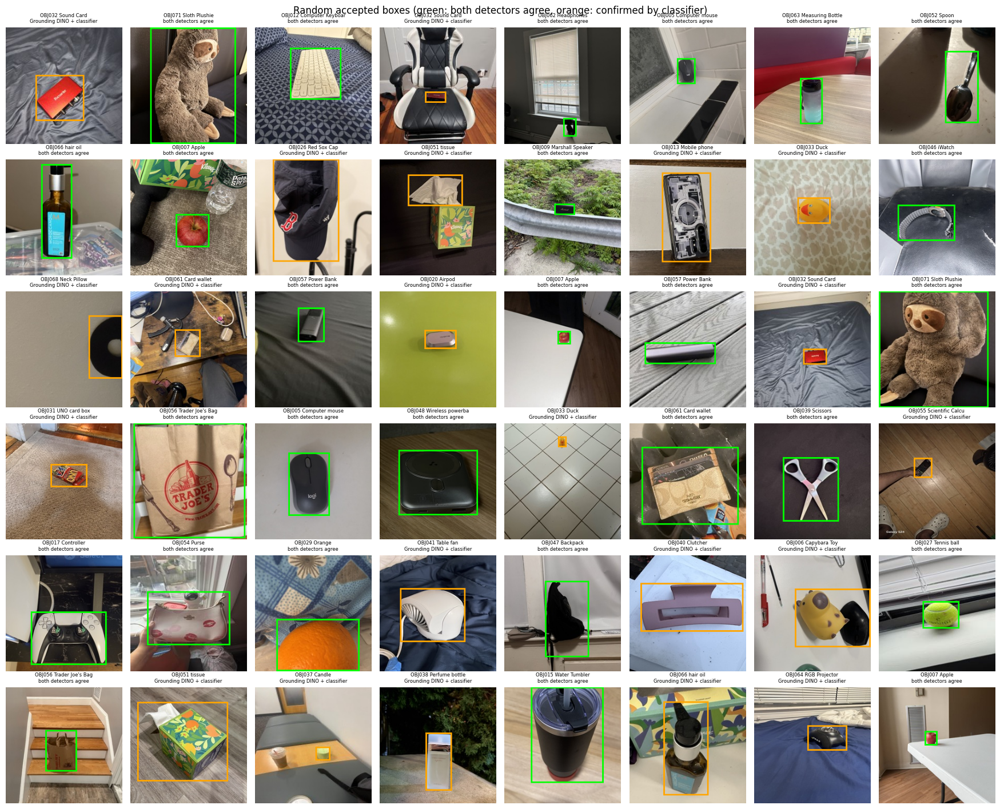

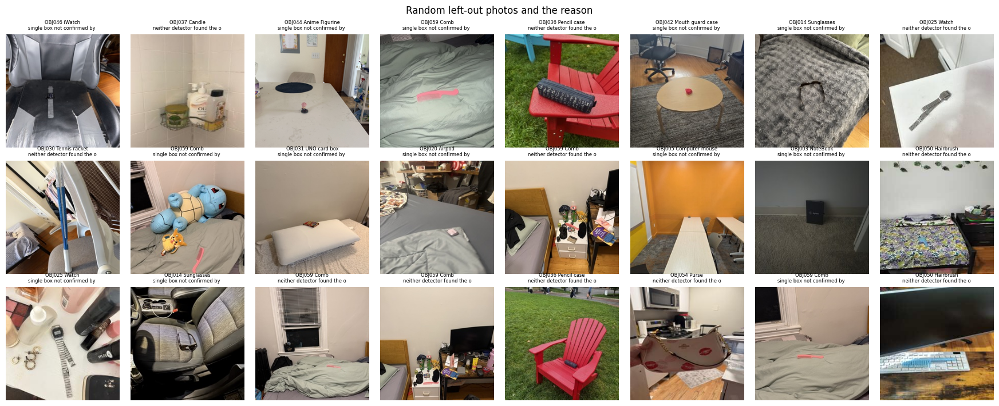

Fill the 'correct' column of label_check_sample.csv (yes/no) to report label accuracy; add wrong ones to MANUAL_REJECT or draw them in manual_boxes.csv and rerun from section 4.


In [10]:
# Visual check: a random sample of accepted boxes, and of left-out photos (evidence for the report)
def sheet_of(rows, title, fname, cols=8):
    rows = list(rows); n = len(rows)
    if not n: print("nothing to show:", title); return
    fig, axes = plt.subplots(math.ceil(n / cols), cols, figsize=(2.2 * cols, 2.4 * math.ceil(n / cols)))
    for ax in np.ravel(axes): ax.axis("off")
    for ax, r in zip(np.ravel(axes), rows):
        im = load_rgb(r.path); d = ImageDraw.Draw(im)
        if r.box: d.rectangle(r.box, outline="lime" if "agree" in r.box_source else "orange", width=3)
        ax.imshow(im); ax.set_title(f"{r.object_id} {NAMES[r.object_id][:16]}\n{r.box_source if r.box else r.exclude_reason[:28]}", fontsize=6)
    fig.suptitle(title); plt.tight_layout(); plt.savefig(FIG_DIR / fname, dpi=120); plt.show()

rng = np.random.default_rng(SEED)
sample = usable.iloc[rng.choice(len(usable), size=min(48, len(usable)), replace=False)]
sheet_of(sample.itertuples(), "Random accepted boxes (green: both detectors agree, orange: confirmed by classifier)", "label_check_accepted.png")
sample[["object_id", "stem", "box_source", "box"]].assign(correct="").to_csv(SAVE_DIR / "label_check_sample.csv", index=False)
out = obj_df[obj_df.box.isna()]
sheet_of(out.iloc[rng.choice(len(out), size=min(24, len(out)), replace=False)].itertuples() if len(out) else [],
         "Random left-out photos and the reason", "label_check_excluded.png")
print("Fill the 'correct' column of label_check_sample.csv (yes/no) to report label accuracy;"
      " add wrong ones to MANUAL_REJECT or draw them in manual_boxes.csv and rerun from section 4.")

## 5. Build the multi-object grid images
* Grid sizes from the TA: **2×2 (448×448), 3×3 (672×672), 4×4 (896×896), 5×4 (1120×896), 5×5 (1120×1120)**, made of 224×224 photos placed side by side.
* A grid uses photos from **one split only**, and each Object ID appears **at most once** per grid (each ID is one physical object).
* About 10 % of cells hold a **background-only photo with no box**, so the model learns that not every cell contains an object.
* Photos are dealt like cards (every photo is used before any is reused), so all photos and classes are used evenly.
* **Train tiles only** are augmented: flip (box mirrored), brightness, contrast, colour, blur or low resolution. Validation and test tiles are original photos.
* Each member generates their own share (file names start with the member's initials); every member has well over 100 multi-object images.
* Labels are YOLO format: `class x_center y_center width height`, normalised to 0 to 1.

In [11]:
class Deck:
    def __init__(self, items, rng): self.items, self.rng, self.stack = list(items), rng, []
    def draw(self):
        if not self.stack: self.stack = [self.items[i] for i in self.rng.permutation(len(self.items))]
        return self.stack.pop()

def augment_tile(im, box, rng):
    x0, y0, x1, y1 = box
    if rng.random() < 0.5:
        im = ImageOps.mirror(im); x0, x1 = TILE - x1, TILE - x0
    im = ImageEnhance.Brightness(im).enhance(rng.uniform(0.65, 1.35))
    im = ImageEnhance.Contrast(im).enhance(rng.uniform(0.75, 1.25))
    im = ImageEnhance.Color(im).enhance(rng.uniform(0.7, 1.3))
    r = rng.random()
    if r < 0.15:
        im = im.filter(ImageFilter.GaussianBlur(rng.uniform(0.5, 1.6)))
    elif r < 0.30:
        f = rng.uniform(2, 3.5); im = im.resize((int(TILE / f), int(TILE / f)), Image.BILINEAR).resize((TILE, TILE), Image.BILINEAR)
    return im, [x0, y0, x1, y1]

def yolo_line(c, b, W, H):
    return f"{c} {(b[0] + b[2]) / 2 / W:.6f} {(b[1] + b[3]) / 2 / H:.6f} {(b[2] - b[0]) / W:.6f} {(b[3] - b[1]) / H:.6f}"

def generate_dataset():
    if YOLO_DIR.exists(): shutil.rmtree(YOLO_DIR)
    manifest = []
    for si, split in enumerate(SPLITS):
        (YOLO_DIR / "images" / split).mkdir(parents=True); (YOLO_DIR / "labels" / split).mkdir(parents=True)
        pool = usable[usable.split == split]
        bgs = list(bg_df[bg_df.split == split].path)
        for mi, ini in enumerate(MEMBERS):
            rng = np.random.default_rng(SEED + 1000 * (mi + 1) + si)
            class_deck = Deck(sorted(pool.object_id.unique()), rng)
            photo_deck = {c: Deck(g.to_dict("records"), rng) for c, g in pool.groupby("object_id")}
            bg_deck = Deck(bgs, rng) if bgs else None
            j = 0
            for (gw, gh), n in GRID_COUNTS[split].items():
                for _ in range(n):
                    j += 1; W, H = gw * TILE, gh * TILE
                    canvas = Image.new("RGB", (W, H), (128, 128, 128)); lines, ids, srcs, bsrcs = [], [], [], []
                    for cell in range(gw * gh):
                        cx, cy = (cell % gw) * TILE, (cell // gw) * TILE
                        if bg_deck and rng.random() < BG_TILE_P:
                            p = bg_deck.draw(); canvas.paste(load_rgb(p), (cx, cy)); bsrcs.append(src_key(p)); continue
                        c = None
                        for _ in range(3 * len(class_deck.items)):
                            cand = class_deck.draw()
                            if cand not in ids: c = cand; break
                        if c is None:                                        # fewer classes than cells: fill with background
                            if bg_deck: p = bg_deck.draw(); canvas.paste(load_rgb(p), (cx, cy)); bsrcs.append(src_key(p))
                            continue
                        r = photo_deck[c].draw(); im, box = load_rgb(r["path"]), list(r["box"])
                        if split == "train" and rng.random() < AUG_P: im, box = augment_tile(im, box, rng)
                        canvas.paste(im, (cx, cy))
                        lines.append(yolo_line(CID[c], [box[0] + cx, box[1] + cy, box[2] + cx, box[3] + cy], W, H))
                        ids.append(c); srcs.append(src_key(r["path"]))
                    name = f"{ini}_{split}_{gw}x{gh}_{j:04d}"
                    canvas.save(YOLO_DIR / "images" / split / f"{name}.jpg", quality=95)
                    (YOLO_DIR / "labels" / split / f"{name}.txt").write_text("\n".join(lines) + ("\n" if lines else ""))
                    manifest.append({"image": f"{name}.jpg", "member": MEMBERS[ini], "split": split, "grid": f"{gw}x{gh}",
                                     "width": W, "height": H, "n_objects": len(ids), "ids": " ".join(ids),
                                     "source_photos": "|".join(srcs), "background_photos": "|".join(bsrcs)})
    man = pd.DataFrame(manifest); man.to_csv(YOLO_DIR / "manifest.csv", index=False)
    return man

DATASET_ZIP = SAVE_DIR / f"yolo_dataset_{'quick' if QUICK_TEST else 'full'}.zip"
if DATASET_ZIP.exists() and not REGENERATE:
    if not YOLO_DIR.exists(): shutil.unpack_archive(str(DATASET_ZIP), str(YOLO_DIR))
    print("Reusing saved dataset", DATASET_ZIP.name)
else:
    t0 = time.time(); generate_dataset()
    shutil.make_archive(str(DATASET_ZIP)[:-4], "zip", YOLO_DIR)
    print(f"Generated in {time.time() - t0:.0f}s and saved to {DATASET_ZIP.name}")
manifest = pd.read_csv(YOLO_DIR / "manifest.csv")

DATA_YAML = YOLO_DIR / "data.yaml"
DATA_YAML.write_text(f"path: {YOLO_DIR.as_posix()}\ntrain: images/train\nval: images/val\ntest: images/test\nnames:\n"
                     + "".join(f"  {i}: {c}\n" for i, c in enumerate(CLASSES)))
shutil.copy(YOLO_DIR / "manifest.csv", SAVE_DIR / "grid_manifest.csv")

Reusing saved dataset yolo_dataset_full.zip


PosixPath('/content/drive/MyDrive/IE7615_project_M2/grid_manifest.csv')

In [12]:
# Dataset summary and checks
summ = manifest.groupby(["member", "split"]).agg(images=("image", "size"), objects=("n_objects", "sum")).unstack("split")
print(summ.to_string())
multi = manifest[manifest.n_objects >= 2].groupby("member").size()
print("\nMulti-object images per member:", multi.to_dict())
assert (multi >= 100).all() or QUICK_TEST, "a member has fewer than 100 multi-object images"
print(manifest.groupby(["split", "grid"]).size().unstack("grid").to_string())

split_of = {src_key(p): s for p, s in zip(obj_df.path, obj_df.split)}
split_of.update({src_key(p): s for p, s in zip(bg_df.path, bg_df.split)})
for _, r in manifest.iterrows():
    used = [u for u in (str(r.source_photos).split("|") + str(r.background_photos).split("|")) if u and u != "nan"]
    assert all(split_of[u] == r.split for u in used), f"{r.image} uses a photo from another split"
    assert len(set(r.ids.split())) == len(r.ids.split()) if isinstance(r.ids, str) else True
print("Checks passed: every grid uses photos from its own split only, and no Object ID repeats inside a grid.")

inst = pd.Series(" ".join(manifest[manifest.split == "train"].ids.dropna()).split()).value_counts().reindex(CLASSES).fillna(0)
print(f"Train boxes per class: min {int(inst.min())}, median {int(inst.median())}, max {int(inst.max())}")
manifest.groupby(["member", "split", "grid"]).size().to_csv(SAVE_DIR / "grid_counts.csv")

                           images           objects           
split                        test train val    test train  val
member                                                        
Mukul Sridar Haladhi           50   200  50     676  2219  659
Praniti Sunil Kale             50   200  50     671  2228  666
Santhoshkumar Chandrasekar     50   200  50     666  2241  676
Tanmayi Shurpali               50   200  50     675  2223  659

Multi-object images per member: {'Mukul Sridar Haladhi': 300, 'Praniti Sunil Kale': 300, 'Santhoshkumar Chandrasekar': 300, 'Tanmayi Shurpali': 300}
grid   2x2  3x3  4x4  5x4  5x5
split                         
test    40   40   40   40   40
train  240  200  160  100  100
val     40   40   40   40   40
Checks passed: every grid uses photos from its own split only, and no Object ID repeats inside a grid.
Train boxes per class: min 119, median 122, max 124


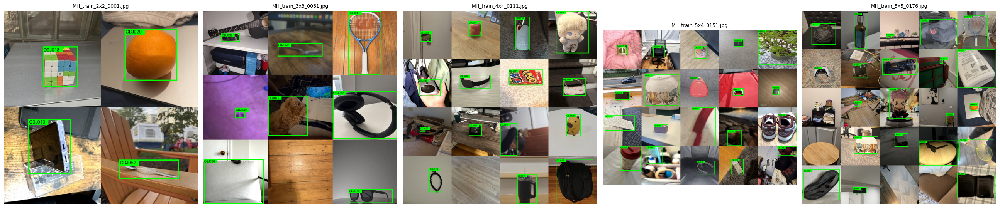

In [13]:
# Look at a few generated grids with their boxes
def read_labels(lbl, W, H):
    out = []
    for line in Path(lbl).read_text().split("\n"):
        if line.strip():
            c, x, y, w, h = line.split(); x, y, w, h = float(x) * W, float(y) * H, float(w) * W, float(h) * H
            out.append((int(c), x - w / 2, y - h / 2, x + w / 2, y + h / 2))
    return out

def draw_boxes(im, boxes, color="lime", confs=None):
    im = im.copy(); d = ImageDraw.Draw(im)
    for i, (c, x0, y0, x1, y1) in enumerate(boxes):
        d.rectangle([x0, y0, x1, y1], outline=color, width=3)
        t = CLASSES[c] + (f" {confs[i]:.2f}" if confs is not None else "")
        d.rectangle([x0, y0, x0 + 7 * len(t) + 4, y0 + 13], fill=color); d.text((x0 + 2, y0 + 1), t, fill="black")
    return im

picks = [manifest[(manifest.split == "train") & (manifest.grid == g)].image.iloc[0] for g in ("2x2", "3x3", "4x4", "5x4", "5x5")]
fig, axes = plt.subplots(1, 5, figsize=(26, 6))
for ax, n in zip(axes, picks):
    im = Image.open(YOLO_DIR / "images" / "train" / n)
    ax.imshow(draw_boxes(im, read_labels(YOLO_DIR / "labels" / "train" / n.replace(".jpg", ".txt"), *im.size))); ax.set_title(n, fontsize=9); ax.axis("off")
plt.tight_layout(); plt.savefig(FIG_DIR / "grid_examples.png", dpi=110); plt.show()

## 6. Train YOLOv8s
| Setting | Value | Why |
|---|---|---|
| Model | YOLOv8s, COCO-pretrained | required YOLOv8; the small size fits a T4 at 1120 px |
| `imgsz` | 1120 | TA tip: close to the largest grid, so objects in 5×5 grids are not shrunk |
| `batch` | 8 | TA tip for Colab; lower to 4 if CUDA runs out of memory |
| Epochs / patience | 80 / 20 | stops early when validation mAP stops improving |
| Mosaic | 0.3, off for the last 10 epochs | our images are already collages, so YOLO's own mosaic is reduced |
| Rotation, MixUp | off | rotation loosens boxes; blending makes pasted photos ambiguous |
| Flip, scale, translate, HSV | 0.5, 0.3, 0.1, defaults | extra variety on top of the tile augmentation |

The run lives on Google Drive: a finished run is skipped, an interrupted run resumes from `last.pt`.

In [14]:
from ultralytics import YOLO
import torch
RUN_NAME = "yolov8s_m2" + ("_quick" if QUICK_TEST else "")
RUN_DIR  = RUNS_DIR / RUN_NAME
BEST, LAST, DONE = RUN_DIR / "weights" / "best.pt", RUN_DIR / "weights" / "last.pt", RUN_DIR / "DONE"
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")

if DONE.exists() and BEST.exists():
    print("Already trained:", BEST)
elif LAST.exists():
    print("Resuming from", LAST); YOLO(str(LAST)).train(resume=True); DONE.write_text(time.ctime())
else:
    YOLO(MODEL).train(data=str(DATA_YAML), imgsz=IMGSZ, epochs=EPOCHS, patience=PATIENCE, batch=BATCH,
                      project=str(RUNS_DIR), name=RUN_NAME, exist_ok=True, seed=SEED, deterministic=True,
                      cos_lr=True, mosaic=0.3, close_mosaic=10, mixup=0.0, degrees=0.0, scale=0.3, translate=0.1,
                      fliplr=0.5, workers=2, amp=True, plots=True, verbose=False)
    DONE.write_text(time.ctime())
print("Best weights:", BEST)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
GPU: Tesla T4
Already trained: /content/drive/MyDrive/IE7615_project_M2/runs/yolov8s_m2/weights/best.pt
Best weights: /content/drive/MyDrive/IE7615_project_M2/runs/yolov8s_m2/weights/best.pt


## 7. Evaluation
* **Standard metrics** on validation and test: precision, recall, **mAP@0.5** and mAP@0.5:0.95.
* **Per grid size** on test, because objects get smaller as grids grow (5×5 is the hardest).
* **Task metrics** at a confidence threshold chosen on validation: share of objects found with the right ID, ID accuracy of found objects, false detections, and fully-correct images.
* Per-class AP, confusion matrix and training curves.

In [15]:
model = YOLO(str(BEST))

def val_metrics(data_yaml, split, tag, plots=False):
    m = model.val(data=str(data_yaml), split=split, imgsz=IMGSZ, batch=BATCH, conf=0.001, iou=0.6,
                  project=str(EVAL_DIR), name=tag, exist_ok=True, plots=plots, verbose=False)
    return m, {"set": tag, "precision": m.box.mp,
               "recall": m.box.mr, "mAP@0.5": m.box.map50, "mAP@0.5:0.95": m.box.map}

m_val, row_val   = val_metrics(DATA_YAML, "val", "val")
m_test, row_test = val_metrics(DATA_YAML, "test", "test", plots=True)

def subset_yaml(grid):
    sub = WORK_DIR / "subsets" / grid
    if sub.exists(): shutil.rmtree(sub)
    (sub / "images").mkdir(parents=True); (sub / "labels").mkdir(parents=True)
    for n in manifest[(manifest.split == "test") & (manifest.grid == grid)].image:
        shutil.copy(YOLO_DIR / "images" / "test" / n, sub / "images" / n)
        shutil.copy(YOLO_DIR / "labels" / "test" / n.replace(".jpg", ".txt"), sub / "labels" / n.replace(".jpg", ".txt"))
    y = sub / "data.yaml"
    y.write_text(f"path: {sub.as_posix()}\ntrain: images\nval: images\nnames:\n" + "".join(f"  {i}: {c}\n" for i, c in enumerate(CLASSES)))
    return y

grid_rows = [val_metrics(subset_yaml(g), "val", f"test_{g}")[1] for g in ("2x2", "3x3", "4x4", "5x4", "5x5")]
METRICS = pd.DataFrame([row_val, row_test] + grid_rows).set_index("set").round(4)
METRICS.to_csv(SAVE_DIR / "metrics_overall_and_per_grid.csv")
METRICS

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,153,835 parameters, 0 gradients, 28.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2159.4±815.4 MB/s, size: 208.3 KB)
val: Scanning /content/m2_work/yolo_dataset/labels/val... 200 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 200/200 1.9Kit/s 0.1s
val: New cache created: /content/m2_work/yolo_dataset/labels/val.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 25/25 2.9it/s 8.6s
                   all        200       2660      0.905      0.888      0.907      0.847
Speed: 2.8ms preprocess, 32.5ms inference, 0.0ms loss, 1.2ms postprocess per image
Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,153,835 parameters, 0 gradients, 28.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2816.7±1577.7 MB/s, size: 3

,precision,recall,mAP@0.5,mAP@0.5:0.95
set,,,,
val,0.9051,0.8882,0.9067,0.8472
test,0.9085,0.9049,0.9191,0.8519
test_2x2,0.8743,0.8624,0.9134,0.8359
test_3x3,0.8754,0.8612,0.9033,0.8429
test_4x4,0.9368,0.9020,0.9348,0.8818
test_5x4,0.8857,0.9014,0.9210,0.8529
test_5x5,0.9080,0.8965,0.9263,0.8585


In [16]:
# Task metrics: does the model name every object correctly, with a good box?
def predict_split(split):
    files = sorted((YOLO_DIR / "images" / split).glob("*.jpg")); out = {}
    for i in range(0, len(files), BATCH):
        for r in model.predict([str(f) for f in files[i:i + BATCH]], imgsz=IMGSZ, conf=0.05, iou=0.6, verbose=False):
            b = r.boxes; out[Path(r.path).name] = (b.cls.cpu().numpy().astype(int), b.conf.cpu().numpy(), b.xyxy.cpu().numpy())
    return out

def score(split, preds, thr):
    rows = []
    for _, mrow in manifest[manifest.split == split].iterrows():
        gt = read_labels(YOLO_DIR / "labels" / split / mrow.image.replace(".jpg", ".txt"), mrow.width, mrow.height)
        c, cf, xy = preds[mrow.image]; k = cf >= thr; c, cf, xy = c[k], cf[k], xy[k]
        used, tp = set(), 0
        for i in np.argsort(-cf):
            best_j, best = None, 0.5
            for j, g in enumerate(gt):
                if j not in used and g[0] == c[i]:
                    v = iou(g[1:], xy[i])
                    if v >= best: best_j, best = j, v
            if best_j is not None: used.add(best_j); tp += 1
        rows.append({"image": mrow.image, "grid": mrow.grid, "n_true": len(gt), "n_pred": len(c), "tp": tp})
    d = pd.DataFrame(rows)
    d["fully_correct"] = (d.tp == d.n_true) & (d.n_pred == d.n_true)
    return d

def summarize(d):
    return {"object_recall": d.tp.sum() / d.n_true.sum(), "detection_precision": d.tp.sum() / max(1, d.n_pred.sum()),
            "fully_correct_images": d.fully_correct.mean()}

P_VAL, P_TEST = predict_split("val"), predict_split("test")
cand = {t: summarize(score("val", P_VAL, t)) for t in np.round(np.arange(0.1, 0.91, 0.05), 2)}
THR = max(cand, key=lambda t: 2 * cand[t]["object_recall"] * cand[t]["detection_precision"]
          / max(1e-9, cand[t]["object_recall"] + cand[t]["detection_precision"]))
d_test = score("test", P_TEST, THR)
TASK = pd.DataFrame({"all test": summarize(d_test)} | {g: summarize(d_test[d_test.grid == g]) for g in ("2x2", "3x3", "4x4", "5x4", "5x5")}).T.round(4)
TASK.to_csv(SAVE_DIR / "task_metrics_test.csv")
print(f"Confidence threshold chosen on validation (best F1): {THR}")
TASK

Confidence threshold chosen on validation (best F1): 0.3


,object_recall,detection_precision,fully_correct_images
all test,0.8943,0.9221,0.225
2x2,0.8621,0.9328,0.575
3x3,0.8716,0.9019,0.275
4x4,0.9048,0.9333,0.225
5x4,0.8955,0.9186,0.050
5x5,0.9000,0.9233,0.000


In [ ]:
# Error analysis on the test grids: which objects were missed, which got the wrong ID
from collections import Counter
recs, conf_pairs, extra = [], Counter(), Counter()
for _, mrow in manifest[manifest.split == "test"].iterrows():
    gt = read_labels(YOLO_DIR / "labels" / "test" / mrow.image.replace(".jpg", ".txt"), mrow.width, mrow.height)
    c, cf, xy = P_TEST[mrow.image]; k = cf >= THR; c, cf, xy = c[k], cf[k], xy[k]
    order = np.argsort(-cf); used_p, used_g = set(), set()
    for i in order:                                    # 1) correct: right ID and IoU >= 0.5
        best_j, best = None, 0.5
        for j, g in enumerate(gt):
            if j not in used_g and g[0] == c[i] and iou(g[1:], xy[i]) >= best: best_j, best = j, iou(g[1:], xy[i])
        if best_j is not None: used_g.add(best_j); used_p.add(i); recs.append((mrow.grid, int(gt[best_j][0]), "correct"))
    for j, g in enumerate(gt):                          # 2) what happened to each object not found correctly
        if j in used_g: continue
        ov = [(iou(g[1:], xy[i]), i) for i in order if i not in used_p]
        v, i = max(ov, default=(0, None))
        if i is not None and v >= 0.5 and c[i] != g[0]:
            used_p.add(i); recs.append((mrow.grid, int(g[0]), "wrong ID")); conf_pairs[(CLASSES[int(g[0])], CLASSES[int(c[i])])] += 1
        elif i is not None and v >= 0.1 and c[i] == g[0]:
            used_p.add(i); recs.append((mrow.grid, int(g[0]), "right ID, poor box"))
        else:
            recs.append((mrow.grid, int(g[0]), "missed"))
    for i in order:                                     # 3) leftover detections
        if i in used_p: continue
        near = max((iou(g[1:], xy[i]) for g in gt), default=0)
        extra["duplicate / part of an object" if near >= 0.1 else "on background (false alarm)"] += 1

E = pd.DataFrame(recs, columns=["grid", "cls", "outcome"])
E["object_id"] = E.cls.map(lambda i: CLASSES[i])
print(f"Test objects: {len(E)}  (threshold {THR})")
summary_err = E.outcome.value_counts().to_frame("objects"); summary_err["share"] = (summary_err.objects / len(E)).round(3)
print(summary_err.to_string())
print("\nExtra detections that match no object:", dict(extra))
print("\nBy grid size (share of objects):")
print(pd.crosstab(E.grid, E.outcome, normalize="index").round(3).to_string())

per_obj = pd.crosstab(E.object_id, E.outcome)
for col in ("correct", "wrong ID", "missed", "right ID, poor box"):
    if col not in per_obj: per_obj[col] = 0
per_obj["test_objects"] = per_obj.sum(axis=1); per_obj["recall"] = (per_obj["correct"] / per_obj.test_objects).round(3)
per_obj["name"] = [NAMES[o] for o in per_obj.index]
per_obj = per_obj.sort_values("recall")
never = per_obj[per_obj.correct == 0]
print(f"\nObject IDs never found correctly on test: {len(never)} of {len(per_obj)}" + (f" -> {list(never.index)}" if len(never) else ""))
print(f"Object IDs with recall below 0.8: {(per_obj.recall < 0.8).sum()}")
print("\nWeakest 10 Object IDs:"); print(per_obj.head(10)[["name", "test_objects", "correct", "wrong ID", "missed", "right ID, poor box", "recall"]].to_string())

pairs = pd.DataFrame([(t, NAMES[t], p, NAMES[p], n) for (t, p), n in conf_pairs.most_common(15)],
                     columns=["true", "true name", "predicted", "predicted name", "times"])
print("\nMost common wrong IDs (true -> predicted):"); print(pairs.to_string(index=False))

summary_err.to_csv(SAVE_DIR / "error_breakdown_test.csv"); per_obj.to_csv(SAVE_DIR / "per_object_errors_test.csv")
pairs.to_csv(SAVE_DIR / "confused_pairs_test.csv", index=False)


Test objects: 2688  (threshold 0.3)
                    objects  share
outcome                           
correct                2404  0.894
missed                  213  0.079
right ID, poor box       54  0.020
wrong ID                 17  0.006

Extra detections that match no object: {'duplicate / part of an object': 44, 'on background (false alarm)': 88}

By grid size (share of objects):
outcome  correct  missed  right ID, poor box  wrong ID
grid                                                  
2x2        0.862   0.117               0.021     0.000
3x3        0.872   0.098               0.024     0.006
4x4        0.905   0.071               0.019     0.005
5x4        0.896   0.075               0.019     0.010
5x5        0.900   0.075               0.020     0.005

Object IDs never found correctly on test: 0 of 73
Object IDs with recall below 0.8: 13

Weakest 10 Object IDs:
outcome                   name  test_objects  correct  wrong ID  missed  right ID, poor box  recall
object_id 

What happened to the 2,688 test objects


                              Objects  Share
Outcome                                     
Correct (right ID, good box)     2404  89.4%
Missed (no box at all)            213   7.9%
Right ID, loose box                54   2.0%
Wrong ID (misclassified)           17   0.6%

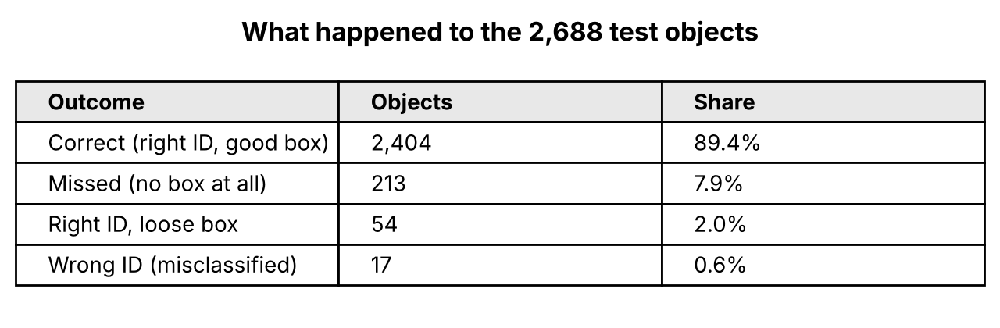

In [ ]:
# Outcome table for the test objects
labels = {"correct": "Correct (right ID, good box)",
          "missed": "Missed (no box at all)",
          "right ID, poor box": "Right ID, loose box",
          "wrong ID": "Wrong ID (misclassified)"}
outcome_table = (E.outcome.value_counts()
                 .reindex(list(labels), fill_value=0)
                 .rename(index=labels)
                 .rename_axis("Outcome")
                 .to_frame("Objects"))
outcome_table["Share"] = (outcome_table.Objects / outcome_table.Objects.sum() * 100).round(1).astype(str) + "%"
print(f"What happened to the {len(E):,} test objects")
display(outcome_table)
outcome_table.to_csv(SAVE_DIR / "outcome_table_test.csv")

# Same table as an image for the report or slides
fig, ax = plt.subplots(figsize=(6.5, 2.2)); ax.axis("off")
tbl = ax.table(cellText=[[o, f"{n:,}", s] for o, (n, s) in outcome_table.iterrows()],
               colLabels=["Outcome", "Objects", "Share"], loc="center", cellLoc="left", colLoc="left")
tbl.auto_set_font_size(False); tbl.set_fontsize(10); tbl.scale(1, 1.6)
for (r, _), cell in tbl.get_celld().items():
    if r == 0: cell.set_text_props(weight="bold"); cell.set_facecolor("#e8e8e8")
ax.set_title(f"What happened to the {len(E):,} test objects", fontweight="bold")
plt.tight_layout(); plt.savefig(FIG_DIR / "outcome_table_test.png", dpi=200, bbox_inches="tight"); plt.show()

Weakest 10 Object IDs (test AP@0.5):
        AP@0.5                 name
OBJ065   0.438         Analog watch
OBJ034   0.589  Table Tennis Racket
OBJ010   0.629        Nike sneakers
OBJ061   0.659          Card wallet
OBJ042   0.741     Mouth guard case
OBJ057   0.754           Power Bank
OBJ025   0.754                Watch
OBJ020   0.760               Airpod
OBJ041   0.776            Table fan
OBJ050   0.777            Hairbrush


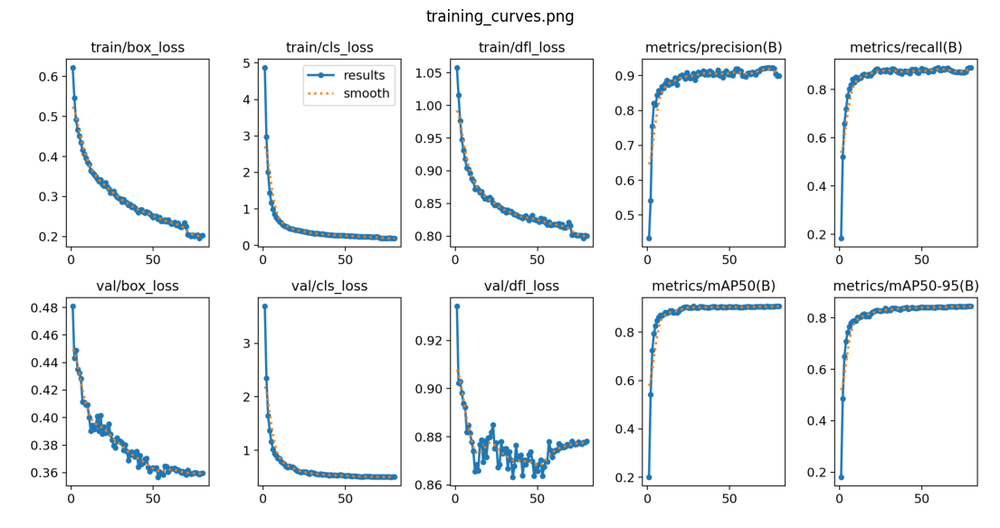

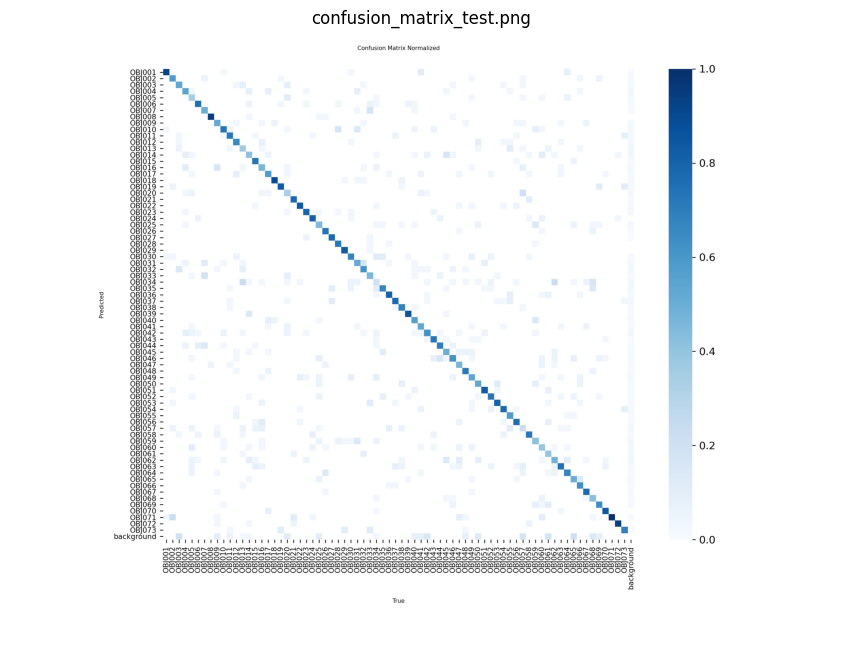

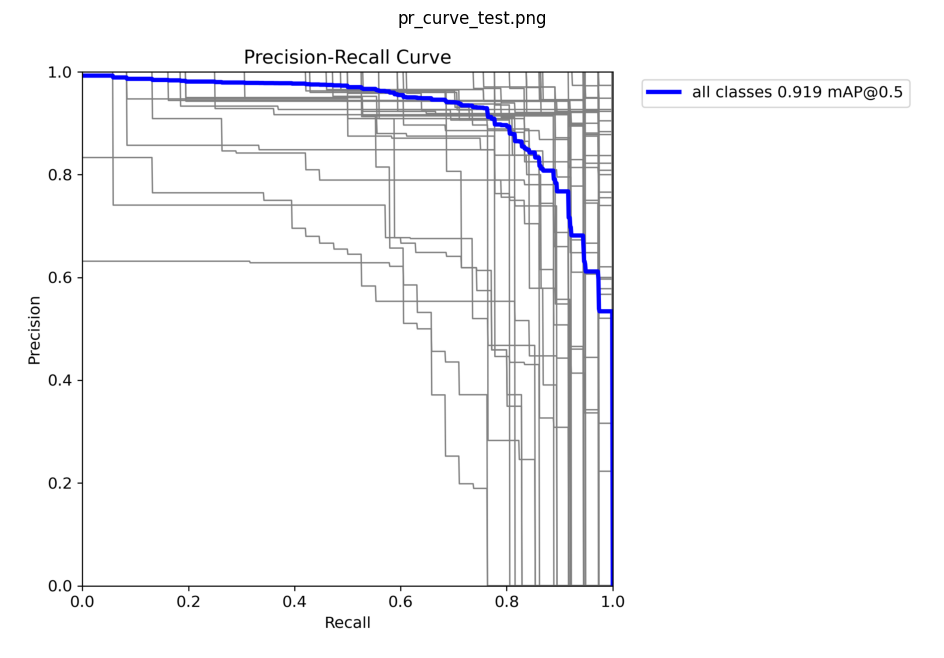

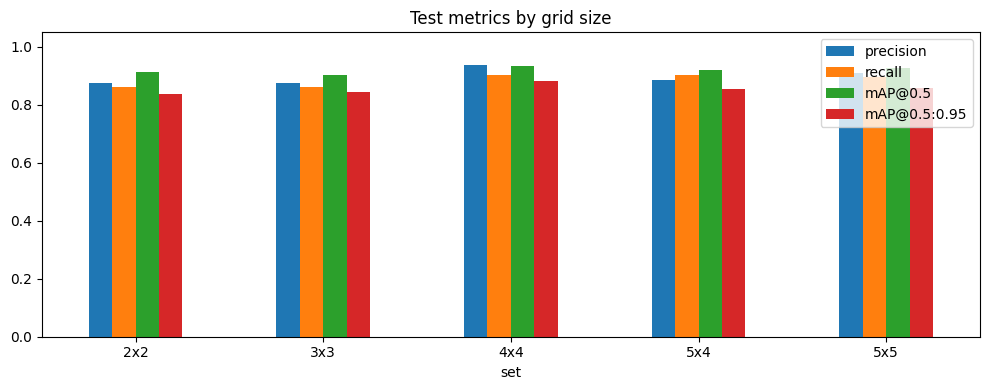

In [17]:
# Per-class AP, confusion matrix, training curves
ap = pd.Series(np.nan, index=CLASSES)
idx = getattr(m_test.box, "ap_class_index", None)
idx = m_test.ap_class_index if idx is None else idx
ap.iloc[np.array(idx, int)] = m_test.box.ap50
per_class = pd.DataFrame({"AP@0.5": ap.round(3), "name": [NAMES[c] for c in CLASSES]}).sort_values("AP@0.5")
per_class.to_csv(SAVE_DIR / "per_class_ap50_test.csv")
print("Weakest 10 Object IDs (test AP@0.5):"); print(per_class.head(10).to_string())

for src, dst in [(RUN_DIR / "results.png", "training_curves.png"),
                 (EVAL_DIR / "test" / "confusion_matrix_normalized.png", "confusion_matrix_test.png"),
                 (EVAL_DIR / "test" / "BoxPR_curve.png", "pr_curve_test.png")]:
    if src.exists():
        shutil.copy(src, FIG_DIR / dst); plt.figure(figsize=(14, 8)); plt.imshow(Image.open(src)); plt.axis("off"); plt.title(dst); plt.show()

ax = METRICS.loc[[f"test_{g}" for g in ("2x2", "3x3", "4x4", "5x4", "5x5")], ["precision", "recall", "mAP@0.5", "mAP@0.5:0.95"]].plot.bar(
    figsize=(10, 4), rot=0, title="Test metrics by grid size")
ax.set_ylim(0, 1.05); ax.set_xticklabels(["2x2", "3x3", "4x4", "5x4", "5x5"]); plt.tight_layout(); plt.savefig(FIG_DIR / "metrics_by_grid.png", dpi=130); plt.show()

## 8. Example detections and `detect_objects()`
`detect_objects(path)` answers requirement 3: for any image it returns one row per detected object with its **Object ID, name, confidence and box** (`x1, y1` top-left and `x2, y2` bottom-right, in pixels), and draws them.

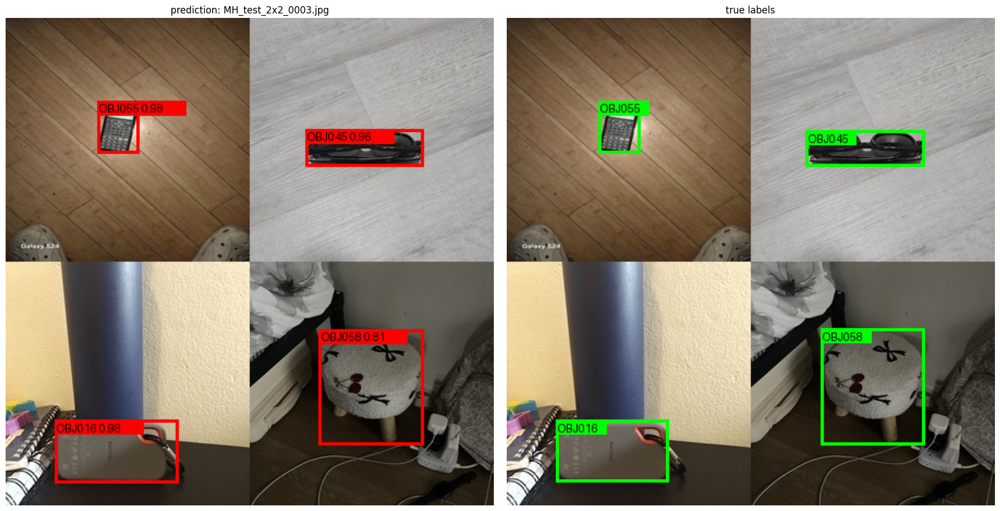

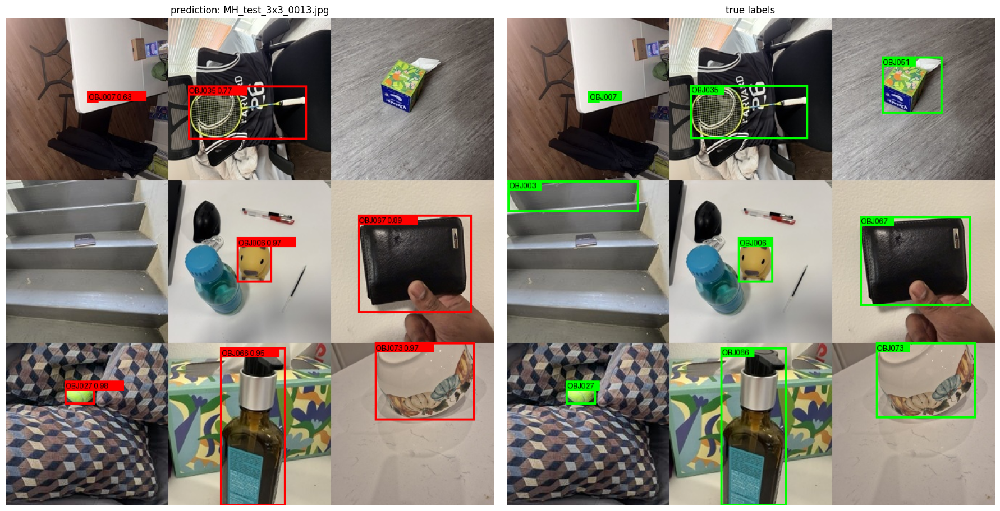

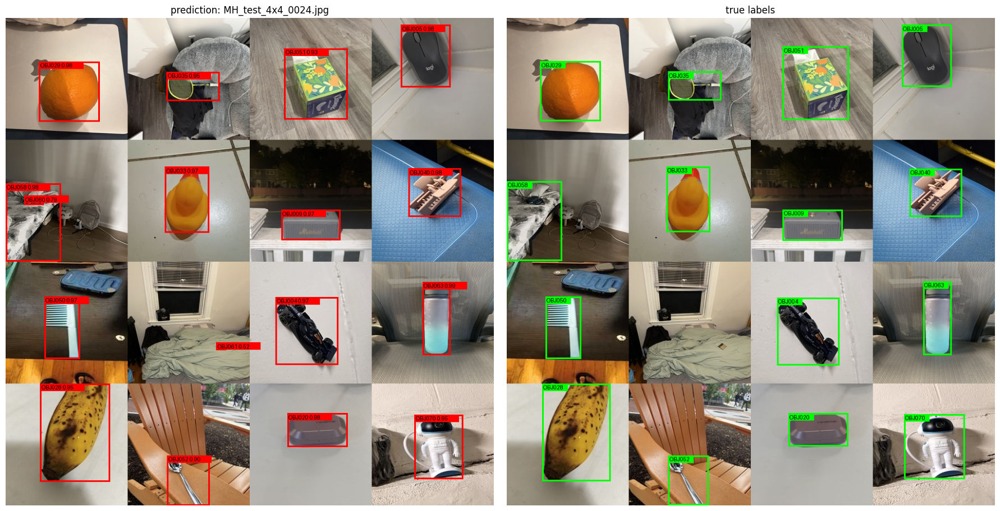

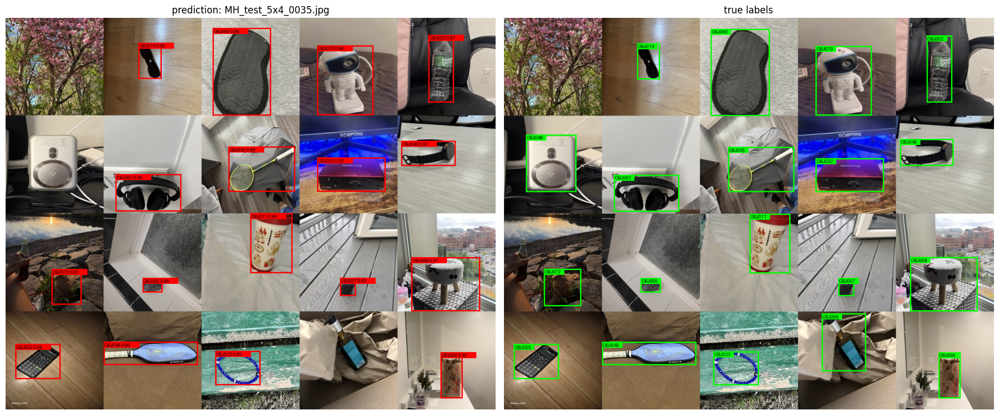

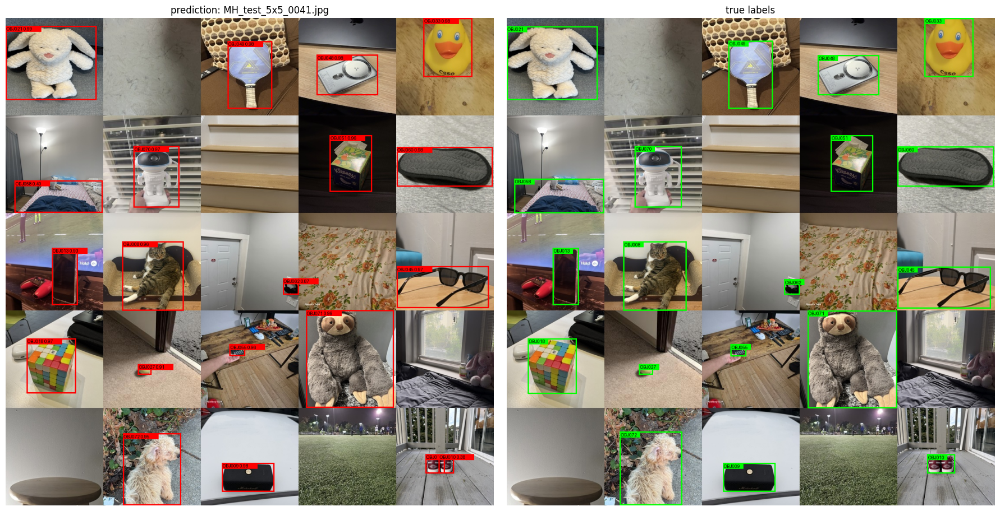

True IDs: OBJ018 OBJ013 OBJ064 OBJ034 OBJ042 OBJ023 OBJ044 OBJ053


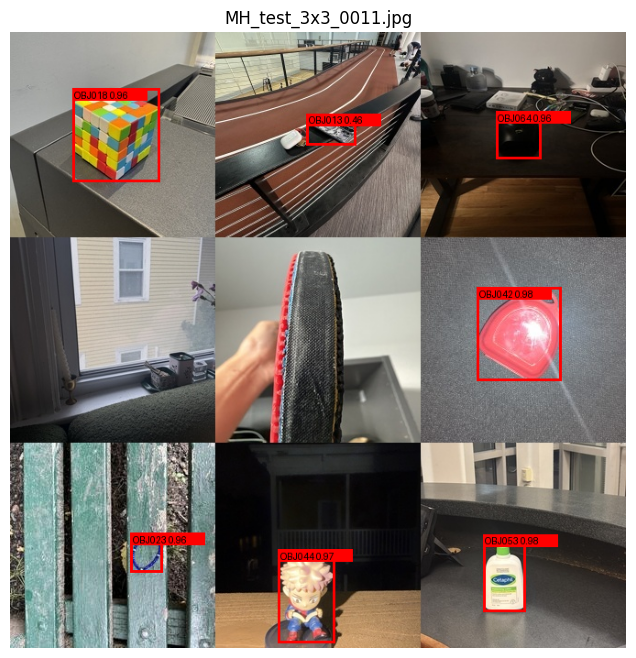

,object_id,name,confidence,x1,y1,x2,y2
0,OBJ018,Rubiks cube,0.959,68.300003,61.799999,163.399994,163.199997
1,OBJ064,RGB Projector,0.964,530.099976,86.800003,579.200012,138.399994
2,OBJ013,Mobile phone,0.462,323.700012,89.000000,377.299988,123.500000
3,OBJ042,Mouth guard case,0.978,509.600006,278.600006,601.700012,380.700012
4,OBJ023,Bracelet,0.962,131.899994,546.799988,166.899994,589.099976
5,OBJ053,Moisturizer,0.981,516.099976,548.299988,562.700012,632.599976
6,OBJ044,Anime Figurine,0.972,292.799988,564.599976,354.899994,666.900024


In [18]:
def detect_objects(path, conf=None, show=True):
    conf = THR if conf is None else conf
    r = model.predict(str(path), imgsz=IMGSZ, conf=conf, iou=0.6, verbose=False)[0]; b = r.boxes
    out = pd.DataFrame({"object_id": [CLASSES[int(c)] for c in b.cls.cpu().numpy()],
                        "name": [NAMES[CLASSES[int(c)]] for c in b.cls.cpu().numpy()],
                        "confidence": b.conf.cpu().numpy().round(3),
                        **dict(zip(["x1", "y1", "x2", "y2"], b.xyxy.cpu().numpy().round(1).T))})
    out = out.sort_values(["y1", "x1"]).reset_index(drop=True)
    if show:
        im = ImageOps.exif_transpose(Image.open(path)).convert("RGB")
        boxes = [(CID[o], x1, y1, x2, y2) for o, x1, y1, x2, y2 in out[["object_id", "x1", "y1", "x2", "y2"]].itertuples(index=False)]
        plt.figure(figsize=(8, 8)); plt.imshow(draw_boxes(im, boxes, "red", out.confidence.values)); plt.axis("off"); plt.title(Path(path).name); plt.show()
    return out

# prediction (left) vs true labels (right), one test image per grid size
rng = np.random.default_rng(1)
for g in ("2x2", "3x3", "4x4", "5x4", "5x5"):
    n = manifest[(manifest.split == "test") & (manifest.grid == g)].image.iloc[int(rng.integers(0, 5))]
    im = Image.open(YOLO_DIR / "images" / "test" / n).convert("RGB")
    c, cf, xy = P_TEST[n]; k = cf >= THR
    pred_im = draw_boxes(im, [(int(a), *b) for a, b in zip(c[k], xy[k])], "red", cf[k])
    true_im = draw_boxes(im, read_labels(YOLO_DIR / "labels" / "test" / n.replace(".jpg", ".txt"), *im.size), "lime")
    fig, (a, b) = plt.subplots(1, 2, figsize=(18, 9))
    a.imshow(pred_im); a.set_title(f"prediction: {n}"); b.imshow(true_im); b.set_title("true labels")
    for x in (a, b): x.axis("off")
    plt.tight_layout(); plt.savefig(FIG_DIR / f"example_detection_{g}.png", dpi=110); plt.show()

demo = manifest[(manifest.split == "test") & (manifest.grid == "3x3")].image.iloc[0]
print("True IDs:", manifest.set_index("image").loc[demo, "ids"])
detect_objects(YOLO_DIR / "images" / "test" / demo)

## 9. Results summary for the report

In [19]:
def md_table(d):
    try: return d.to_markdown()
    except ImportError: return "```\n" + d.to_string() + "\n```"

lines = [
    "# IE7615 Milestone 2: results summary (Group 7)", "",
    f"- Object IDs used: {len(CLASSES)} ({'SECTION-01 subset' if USE_SECTION_01 else 'all objects' if not SUBSET_IDS else 'custom subset'})",
    f"- Grid sizes: 2x2, 3x3, 4x4, 5x4, 5x5 of 224x224 photos | images: " + ", ".join(f"{s} {(manifest.split == s).sum()}" for s in SPLITS),
    f"- Multi-object images per member: {manifest[manifest.n_objects >= 2].groupby('member').size().to_dict()}",
    f"- Object photos: {len(obj_df)}; labelled: {len(usable)}; left out: {len(obj_df) - len(usable)} ({frac_out:.1%}, limit 20%)",
    f"- Label sources: {obj_df.box_source.value_counts().to_dict()}",
    f"- Model: YOLOv8s, imgsz {IMGSZ}, batch {BATCH}; confidence threshold {THR} (chosen on validation)", "",
    "## Data cleaning", md_table(pd.Series(clean_log, name="value").to_frame()), "",
    "## Detection metrics (validation, test, and test per grid size)", md_table(METRICS), "",
    "## Task metrics on test", md_table(TASK), "",
    "## Weakest Object IDs (test AP@0.5)", md_table(per_class.head(10)), "",
    "## Photos left out per Object ID (top 10)", md_table(excl.head(10)),
]
Path(SAVE_DIR, "results_summary_m2.md").write_text("\n".join(lines), encoding="utf-8")
print("\n".join(lines)); print("\nAll outputs saved in", SAVE_DIR)

# IE7615 Milestone 2: results summary (Group 7)

- Object IDs used: 73 (all objects)
- Grid sizes: 2x2, 3x3, 4x4, 5x4, 5x5 of 224x224 photos | images: train 800, val 200, test 200
- Multi-object images per member: {'Mukul Sridar Haladhi': 300, 'Praniti Sunil Kale': 300, 'Santhoshkumar Chandrasekar': 300, 'Tanmayi Shurpali': 300}
- Object photos: 6936; labelled: 6388; left out: 548 (7.9%, limit 20%)
- Label sources: {'Grounding DINO + classifier': 3319, 'both detectors agree': 2903, 'excluded': 548, 'YOLO-World + classifier': 166}
- Model: YOLOv8s, imgsz 1120, batch 8; confidence threshold 0.3 (chosen on validation)

## Data cleaning
|                                      | value                                                                                         |
|:-------------------------------------|:----------------------------------------------------------------------------------------------|
| files indexed                        | 7343                                        